# Étudiant 1 — Dataset & Baseline (Nada)

Notebook simple, à exécuter **de haut en bas** sur Google Colab (GPU T4 : `Exécution → Modifier le type d'exécution`).

| Tâche demandée | Où dans le notebook |
|---|---|
| 1. Choisir un dataset | Étape 1 |
| 2. Télécharger avec HF Datasets | Étape 1 |
| 3. Nettoyer avec Pandas | Étape 2 |
| 5. Split Train / Val / Test | Étape 3 |
| 4. Tokenisation (HF Tokenizers) | Étape 4 |
| 6-7. Modèle DistilBERT (HF Transformers) | Étape 5 |
| 8. Baseline | Étape 6 |
| 9. Comparaison des learning rates | Étape 7 |

**Livrables** : `data/*.csv`, code de preprocessing, modèle fonctionnel, résultats baseline, `results/comparaison_lr.csv` + figures.

**Pour les collègues** : la fonction `run()` (étape 6) accepte `nom`, `optimizer`,
`batch_size`, `scheduler`, `warmup_ratio` et `seed`. Changez **un seul** paramètre par
rapport à la baseline, et donnez un `nom` unique à chaque expérience : le dictionnaire
`results` est indexé par **nom d'expérience**, pas par learning rate. Vous pouvez donc
tester `run(2e-5, nom="exp_05_warmup01", warmup_ratio=0.1)` sans écraser la baseline.
**Version partagée** : ce notebook contient les sorties de l'exécution de référence
(Colab, GPU T4, seed 42). Pour reproduire, exécutez-le de haut en bas.

**Paramètres communs (à ne pas changer, sauf celui étudié)**

| Paramètre | Valeur |
|---|---|
| Modèle | distilbert-base-uncased |
| max_len | 128 |
| epochs | 2 |
| batch size (baseline) | 32 |
| learning rate (baseline) | 2e-5 |
| optimizer (baseline) | AdamW, weight_decay=0.01 |
| scheduler / warmup | linéaire / 0 |
| gradient clipping | 1.0 |
| précision mixte | fp16 (AMP) sur GPU |
| seed | 42 |
| sélection du modèle | meilleur checkpoint sur le F1 de validation (évalué tous les 50 pas) |

**Règles** : changer **un seul** paramètre par expérience, donner un `nom` unique,
et choisir sur la **validation**, jamais sur le test.

⚠️ **SGD** : lr=2e-5 est trop faible, choisir et justifier un autre lr (ex. 1e-2 à 1e-1).
⚠️ **Batch size** : le nombre de pas change, donc comparer les courbes en nombre d'exemples vus, pas en pas.

## Ce qui a été corrigé dans cette version

- `results` est indexé par **nom d'expérience** (ex. `exp_01_baseline`) : plus de collision
  quand un collègue garde le même LR mais change warmup/scheduler/batch/optimizer.
- Le **meilleur checkpoint selon le F1 de validation** est rechargé avant l'évaluation test
  (au lieu des derniers poids, qui pouvaient être dégradés).
- `cudnn.deterministic=True` ajouté à `set_seed()` pour une meilleure reproductibilité.
- `tokenizer.encode(..., truncation=True)` évite le warning sur les séquences > 512 tokens.
- Note ajoutée sur le *load report* `UNEXPECTED / MISSING` de DistilBERT (comportement normal).
- Découpage Train/Val/Test **stratifié** ; validation et test ne servent pas aux mêmes choses
  (la sélection se fait sur la validation, le test n'est qu'une information finale).

In [1]:
!pip install -q transformers datasets scikit-learn pandas matplotlib

In [2]:
import os, re, html, random, time, json
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from datasets import load_dataset, Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_scheduler
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import DataLoader

# ---- Paramètres communs (identiques pour TOUTES les expériences) ----
SEED = 42
MODEL = "distilbert-base-uncased"
MAX_LEN = 128
BATCH = 32
EPOCHS = 2
BASELINE_LR = 2e-5
OTHER_LRS = [1e-5, 5e-5, 1e-4]
EVAL_EVERY = 50          # évaluation sur la validation tous les 50 pas (courbes de convergence)
TEAM_BUDGET = 15         # quota d'entraînements pour toute l'équipe

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("Device :", device)

os.makedirs("data", exist_ok=True)
os.makedirs("results", exist_ok=True)

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

# Noms d'expériences : clés stables dans `results` (un seul paramètre change par run).
NOM_BASELINE = "exp_01_baseline"
NOMS_LR = {1e-5: "exp_02_lr_1e-5", 5e-5: "exp_03_lr_5e-5", 1e-4: "exp_04_lr_1e-4"}

Device : cuda


## Étape 1 — Choix et téléchargement du dataset

**IMDB** (critiques de films, classification binaire négatif/positif) : dataset de référence pour la classification de texte, équilibré, en anglais, directement disponible dans Hugging Face Datasets, et adapté à un petit Transformer comme DistilBERT.

In [3]:
raw = load_dataset("stanfordnlp/imdb")
print(raw)
train_full = raw["train"].to_pandas()
test_full = raw["test"].to_pandas()
print(train_full.shape, test_full.shape)

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})
(25000, 2) (25000, 2)


## Étape 2 — Nettoyage avec Pandas

In [4]:
def clean_text(t):
    t = html.unescape(str(t))                 # &amp; -> &, &quot; -> "
    t = re.sub(r"<[^>]+>", " ", t)            # supprime les balises HTML (<br />)
    t = re.sub(r"\s+", " ", t).strip()        # espaces multiples
    return t

def clean_df(df):
    df = df[["text", "label"]].dropna().copy()
    df["text"] = df["text"].map(clean_text)
    df = df[df["text"].str.len() > 0]
    return df.drop_duplicates(subset=["text"]).reset_index(drop=True)

# Preuve du preprocessing : avant / après
exemple = min((t for t in train_full["text"] if "<br" in t), key=len)
print("AVANT :", exemple[:400])
print("APRES :", clean_text(exemple)[:400])

train_clean = clean_df(train_full)
test_clean = clean_df(test_full)
print(f"\nTrain : {len(train_full)} -> {len(train_clean)} | Test : {len(test_full)} -> {len(test_clean)}")
print("Labels (train) :", train_clean["label"].value_counts().to_dict())

AVANT : The only remarkable fact is the participation of Klaus Kinski who plays a priest. Don't ask me why he does it! A bad, bad movie overall.<br /><br />
APRES : The only remarkable fact is the participation of Klaus Kinski who plays a priest. Don't ask me why he does it! A bad, bad movie overall.

Train : 25000 -> 24902 | Test : 25000 -> 24799
Labels (train) : {1: 12471, 0: 12431}


## Étape 3 — Split Train / Validation / Test (4000 / 1000 / 1000)

On sous-échantillonne pour tenir dans le budget GPU. Le test est tiré du split `test` d'IMDB et on retire tout texte déjà vu en train/val (pas de fuite de données).

In [12]:
from sklearn.model_selection import train_test_split

# 5000 exemples stratifiés, puis 4000 train / 1000 val (même proportion de classes)
sub, _ = train_test_split(train_clean, train_size=5000,
                          stratify=train_clean["label"], random_state=SEED)
train_df, val_df = train_test_split(sub, train_size=4000,
                                    stratify=sub["label"], random_state=SEED)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

# Test : tiré du split test d'IMDB, sans aucun texte déjà vu, stratifié aussi
vus = set(train_df["text"]) | set(val_df["text"])
pool_test = test_clean[~test_clean["text"].isin(vus)]
test_df, _ = train_test_split(pool_test, train_size=1000,
                              stratify=pool_test["label"], random_state=SEED)
test_df = test_df.reset_index(drop=True)

assert not (set(train_df["text"]) & set(test_df["text"])), "Fuite train/test !"
assert not (set(train_df["text"]) & set(val_df["text"])), "Fuite train/val !"
assert not (set(val_df["text"]) & set(test_df["text"])), "Fuite val/test !"

for nom, d in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    d.to_csv(f"data/{nom}.csv", index=False)
    print(f"{nom:<11}: {len(d)} lignes | labels = {d['label'].value_counts().to_dict()}")

train      : 4000 lignes | labels = {1: 2003, 0: 1997}
validation : 1000 lignes | labels = {1: 501, 0: 499}
test       : 1000 lignes | labels = {1: 502, 0: 498}


## Étape 4 — Tokenisation (Hugging Face)

Longueur moyenne : 265 tokens | médiane : 223
Avis tronqués à 128 tokens : 88.3 % | à 256 tokens : 41.9 %


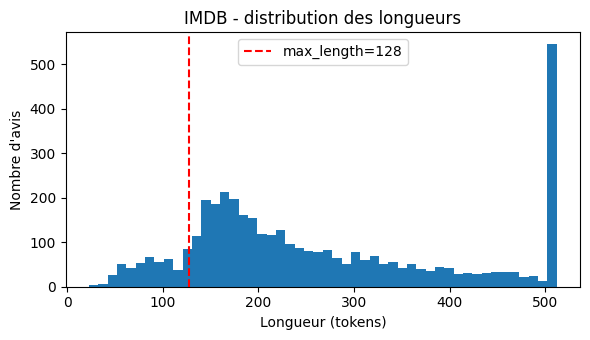

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 4000
})


In [13]:
tokenizer = AutoTokenizer.from_pretrained(MODEL)

# Analyse des longueurs : justifie le choix de max_length
longueurs = pd.Series([len(tokenizer.encode(t, truncation=True, max_length=512)) for t in train_df["text"]])
pct128 = round(100 * (longueurs > 128).mean(), 1)
pct256 = round(100 * (longueurs > 256).mean(), 1)
print(f"Longueur moyenne : {longueurs.mean():.0f} tokens | médiane : {longueurs.median():.0f}")
print(f"Avis tronqués à 128 tokens : {pct128} % | à 256 tokens : {pct256} %")

plt.figure(figsize=(6, 3.5))
plt.hist(longueurs, bins=50)
plt.axvline(MAX_LEN, color="red", linestyle="--", label=f"max_length={MAX_LEN}")
plt.xlabel("Longueur (tokens)"); plt.ylabel("Nombre d'avis"); plt.legend()
plt.title("IMDB - distribution des longueurs"); plt.tight_layout()
plt.savefig("results/longueur_textes.png", dpi=150); plt.show()

def vers_dataset(df):
    ds = Dataset.from_pandas(df[["text", "label"]], preserve_index=False)
    ds = ds.map(lambda b: tokenizer(b["text"], truncation=True,
                                    padding="max_length", max_length=MAX_LEN),
                batched=True, remove_columns=["text"])
    ds = ds.rename_column("label", "labels")
    ds.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
    return ds

ds_train, ds_val, ds_test = vers_dataset(train_df), vers_dataset(val_df), vers_dataset(test_df)
print(ds_train)

## Étape 5 — Chargement du modèle (DistilBERT)

DistilBERT : ~66 M de paramètres, 40 % plus léger que BERT, bien adapté à un entraînement rapide sur T4.

> Le *load report* affiché au chargement (`UNEXPECTED` pour la tête de pré-entraînement,
> `MISSING` pour `classifier.*`) est **normal** : la tête de classification est
> réinitialisée pour notre tâche binaire. Ce n'est pas une erreur.

In [14]:
m = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=2)
print(f"Paramètres : {sum(p.numel() for p in m.parameters())/1e6:.1f} M")
del m  # on recharge un modèle neuf à chaque expérience

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Paramètres : 67.0 M


## Étape 6 — Fonction d'entraînement + Baseline

**Baseline** : AdamW (lr = 2e-5), batch 32, scheduler linéaire, **warmup = 0**, 2 époques, seed 42.

Pour chaque run on garde la loss d'entraînement **à chaque pas** et la loss/F1 de validation tous les 50 pas, pour tracer de vraies courbes de convergence. Le test n'est évalué qu'**une fois, à la fin**.

In [15]:
def evaluer(model, loader):
    model.eval()
    perte, preds, refs = 0.0, [], []
    with torch.no_grad():
        for b in loader:
            b = {k: v.to(device) for k, v in b.items()}
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(**b)
            perte += out.loss.item()
            preds += out.logits.argmax(-1).cpu().tolist()
            refs += b["labels"].cpu().tolist()
    return perte / len(loader), preds, refs

def metriques(refs, preds):
    p, r, f1, _ = precision_recall_fscore_support(refs, preds, average="binary", zero_division=0)
    return {"accuracy": accuracy_score(refs, preds), "precision": p, "recall": r, "f1": f1}

def run(lr, nom=None, optimizer="adamw", batch_size=BATCH, scheduler="linear", warmup_ratio=0.0, seed=SEED):
    if nom is None:
        nom = f"lr_{lr:g}"
    set_seed(seed)
    if use_amp: torch.cuda.reset_peak_memory_stats()
    g = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(ds_train, batch_size=batch_size, shuffle=True, generator=g)
    val_loader = DataLoader(ds_val, batch_size=64)
    test_loader = DataLoader(ds_test, batch_size=64)

    model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=2).to(device)
    if optimizer == "adamw":
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    total = len(train_loader) * EPOCHS
    sched = get_scheduler(scheduler, opt, num_warmup_steps=int(warmup_ratio * total), num_training_steps=total)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    step_loss, val_curve, t_train, step = [], [], 0.0, 0
    meilleur_f1, meilleur_step, meilleur_etat, meilleur_vl = -1.0, 0, None, None
    for epoch in range(EPOCHS):
        for b in train_loader:
            model.train(); t0 = time.perf_counter()
            b = {k: v.to(device) for k, v in b.items()}
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                loss = model(**b).loss
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            step_loss.append(loss.item())                       # loss à CHAQUE pas
            t_train += time.perf_counter() - t0                 # temps hors évaluation
            step += 1
            if step % EVAL_EVERY == 0 or step == total:
                vl, pv, rv = evaluer(model, val_loader)
                f1_val = metriques(rv, pv)["f1"]
                val_curve.append({"step": step, "val_loss": vl, "val_f1": f1_val})
                if f1_val > meilleur_f1:
                    meilleur_f1, meilleur_step, meilleur_vl = f1_val, step, vl
                    meilleur_etat = {k: v.detach().cpu().clone()
                                     for k, v in model.state_dict().items()}
                print(f"{nom} (lr={lr:g}) | pas {step}/{total} | "
                      f"train_loss={np.mean(step_loss[-10:]):.4f} "
                      f"| val_loss={vl:.4f} | val_f1={f1_val:.4f}")

    # On évalue le test avec le MEILLEUR modèle selon la validation, pas les derniers poids.
    if meilleur_etat is not None:
        model.load_state_dict(meilleur_etat)
    _, pt, rt = evaluer(model, test_loader)                     # test : UNE seule fois, à la fin
    res = {"nom": nom, "learning_rate": lr, "optimizer": optimizer, "batch_size": batch_size,
           "scheduler": scheduler, "warmup_ratio": warmup_ratio, "seed": seed, **metriques(rt, pt),
           "best_val_f1": round(meilleur_f1, 4), "best_val_loss": round(meilleur_vl, 4),
           "last_val_f1": val_curve[-1]["val_f1"],
           "best_step": meilleur_step,
           "temps_train_s": round(t_train, 1),
           "gpu_mem_mb": round(torch.cuda.max_memory_allocated() / 1024**2) if use_amp else 0,
           "step_loss": step_loss, "val_curve": val_curve,
           "cm": confusion_matrix(rt, pt, labels=[0, 1]).tolist()}
    print(f"TEST {nom} (lr={lr:g}) -> acc={res['accuracy']:.4f} f1={res['f1']:.4f} "
          f"| meilleur pas={meilleur_step} | {res['temps_train_s']} s")
    del model, opt; torch.cuda.empty_cache()
    return res

results = {}
results[NOM_BASELINE] = run(BASELINE_LR, nom=NOM_BASELINE)   # BASELINE
print(f"\n[budget] {len(results)} entraînement(s) utilisé(s) sur {TEAM_BUDGET} pour l'équipe")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


exp_01_baseline (lr=2e-05) | pas 50/250 | train_loss=0.4213 | val_loss=0.4367 | val_f1=0.8192
exp_01_baseline (lr=2e-05) | pas 100/250 | train_loss=0.4054 | val_loss=0.4033 | val_f1=0.8385
exp_01_baseline (lr=2e-05) | pas 150/250 | train_loss=0.3083 | val_loss=0.3816 | val_f1=0.8428
exp_01_baseline (lr=2e-05) | pas 200/250 | train_loss=0.3037 | val_loss=0.3705 | val_f1=0.8470
exp_01_baseline (lr=2e-05) | pas 250/250 | train_loss=0.3185 | val_loss=0.3777 | val_f1=0.8340
TEST exp_01_baseline (lr=2e-05) -> acc=0.8560 f1=0.8571 | meilleur pas=200 | 28.0 s

[budget] 1 entraînement(s) utilisé(s) sur 15 pour l'équipe


## Étape 7 — Comparaison des learning rates

Seul `learning_rate` change. **Budget Étudiant 1 : 4 entraînements** (baseline + 3) sur les 15 de l'équipe, soit 11 restants pour les autres études.

In [16]:
for lr in OTHER_LRS:
    nom = NOMS_LR[lr]
    results[nom] = run(lr, nom=nom)
print(f"[budget] {len(results)} entraînement(s) utilisé(s) sur {TEAM_BUDGET} pour l'équipe")
json.dump({str(k): v for k, v in results.items()}, open("results/all_runs.json", "w"))  # courbes réutilisables

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


exp_02_lr_1e-5 (lr=1e-05) | pas 50/250 | train_loss=0.6322 | val_loss=0.6076 | val_f1=0.6935
exp_02_lr_1e-5 (lr=1e-05) | pas 100/250 | train_loss=0.4385 | val_loss=0.4232 | val_f1=0.8332
exp_02_lr_1e-5 (lr=1e-05) | pas 150/250 | train_loss=0.3570 | val_loss=0.3863 | val_f1=0.8426
exp_02_lr_1e-5 (lr=1e-05) | pas 200/250 | train_loss=0.3588 | val_loss=0.3795 | val_f1=0.8363
exp_02_lr_1e-5 (lr=1e-05) | pas 250/250 | train_loss=0.3628 | val_loss=0.3857 | val_f1=0.8217
TEST exp_02_lr_1e-5 (lr=1e-05) -> acc=0.8500 f1=0.8482 | meilleur pas=150 | 26.7 s


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


exp_03_lr_5e-5 (lr=5e-05) | pas 50/250 | train_loss=0.4033 | val_loss=0.4296 | val_f1=0.8237
exp_03_lr_5e-5 (lr=5e-05) | pas 100/250 | train_loss=0.4140 | val_loss=0.3707 | val_f1=0.8206
exp_03_lr_5e-5 (lr=5e-05) | pas 150/250 | train_loss=0.2276 | val_loss=0.4168 | val_f1=0.8587
exp_03_lr_5e-5 (lr=5e-05) | pas 200/250 | train_loss=0.2339 | val_loss=0.3692 | val_f1=0.8586
exp_03_lr_5e-5 (lr=5e-05) | pas 250/250 | train_loss=0.2521 | val_loss=0.3974 | val_f1=0.8372
TEST exp_03_lr_5e-5 (lr=5e-05) -> acc=0.8500 f1=0.8590 | meilleur pas=150 | 27.1 s


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


exp_04_lr_1e-4 (lr=0.0001) | pas 50/250 | train_loss=0.4110 | val_loss=0.3991 | val_f1=0.8475
exp_04_lr_1e-4 (lr=0.0001) | pas 100/250 | train_loss=0.4168 | val_loss=0.3690 | val_f1=0.8402
exp_04_lr_1e-4 (lr=0.0001) | pas 150/250 | train_loss=0.2368 | val_loss=0.5102 | val_f1=0.8441
exp_04_lr_1e-4 (lr=0.0001) | pas 200/250 | train_loss=0.2065 | val_loss=0.3943 | val_f1=0.8513
exp_04_lr_1e-4 (lr=0.0001) | pas 250/250 | train_loss=0.2098 | val_loss=0.4328 | val_f1=0.8424
TEST exp_04_lr_1e-4 (lr=0.0001) -> acc=0.8580 f1=0.8616 | meilleur pas=200 | 26.9 s
[budget] 4 entraînement(s) utilisé(s) sur 15 pour l'équipe


,nom,learning_rate,optimizer,batch_size,scheduler,warmup_ratio,best_val_f1,best_val_loss,best_step,temps_train_s,gpu_mem_mb,accuracy,precision,recall,f1
0,exp_02_lr_1e-5,0.00001,adamw,32,linear,0.0,0.8426,0.3863,150,26.7,1724,0.850,0.8621,0.8347,0.8482
1,exp_01_baseline,0.00002,adamw,32,linear,0.0,0.8470,0.3705,200,28.0,1721,0.856,0.8538,0.8606,0.8571
2,exp_03_lr_5e-5,0.00005,adamw,32,linear,0.0,0.8587,0.4168,150,27.1,1721,0.850,0.8132,0.9104,0.8590
3,exp_04_lr_1e-4,0.00010,adamw,32,linear,0.0,0.8513,0.3943,200,26.9,1720,0.858,0.8435,0.8805,0.8616


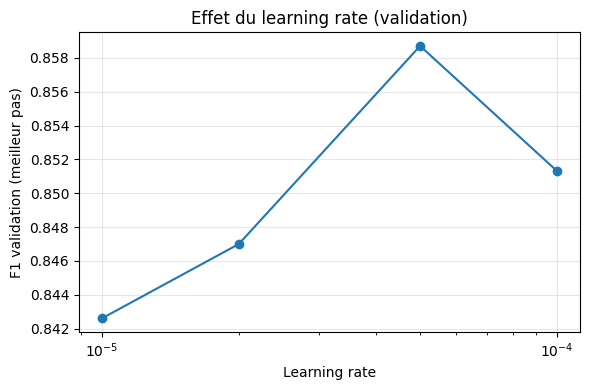

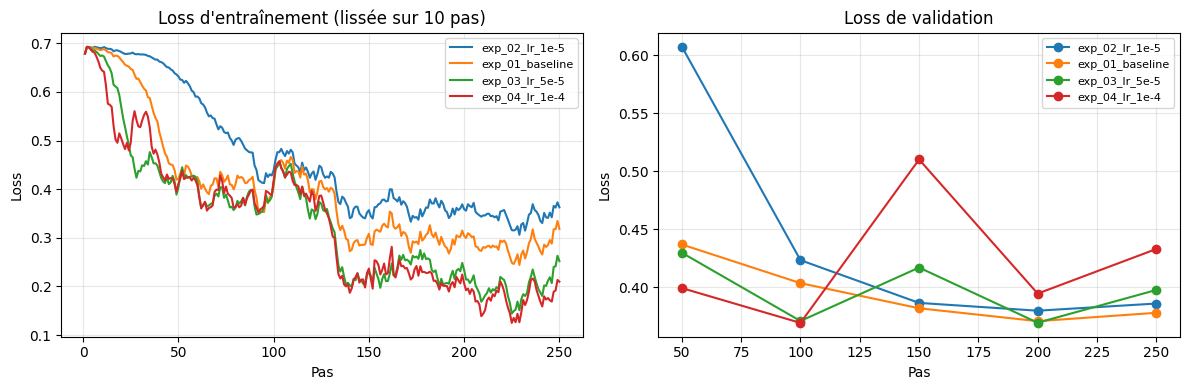

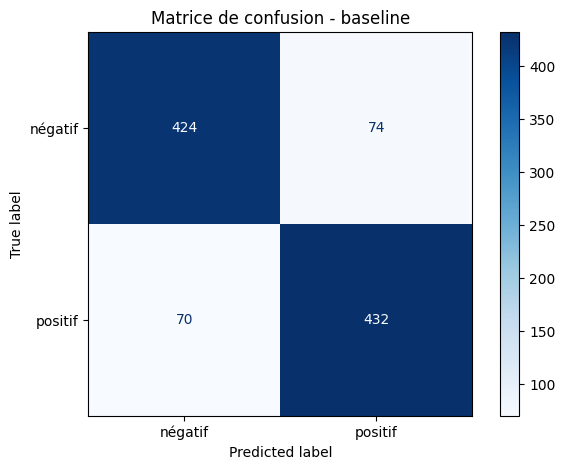

Baseline (lr=2e-05) : best_val_f1=0.8470.
exp_02_lr_1e-5 : best_val_f1=0.8426 (-0.0044 vs baseline), val_loss=0.3863, temps=26.7 s.
exp_03_lr_5e-5 : best_val_f1=0.8587 (+0.0117 vs baseline), val_loss=0.4168, temps=27.1 s.
exp_04_lr_1e-4 : best_val_f1=0.8513 (+0.0043 vs baseline), val_loss=0.3943, temps=26.9 s.
Meilleur lr selon la validation : 5e-05. Test de cette config : accuracy=0.8500, F1=0.8590.
Limites : 4000 exemples, 2 époques, une seule seed, validation et test de 1000 exemples (marge d'erreur ≈ ±2 points : des écarts plus petits ne sont pas concluants), 88.3 % des avis tronqués à 128 tokens.
Baseline (lr=2e-05) : best_val_f1=0.8470.
exp_02_lr_1e-5 : best_val_f1=0.8426 (-0.0044 vs baseline), val_loss=0.3863, temps=26.7 s.
exp_03_lr_5e-5 : best_val_f1=0.8587 (+0.0117 vs baseline), val_loss=0.4168, temps=27.1 s.
exp_04_lr_1e-4 : best_val_f1=0.8513 (+0.0043 vs baseline), val_loss=0.3943, temps=26.9 s.
Meilleur lr selon la validation : 5e-05. Test de cette config : accuracy=0.8500

In [21]:
# Runs de l'étude learning rate (baseline + 3), triés par lr
lr_runs = sorted([results[NOM_BASELINE]] + [results[NOMS_LR[l]] for l in OTHER_LRS],
                 key=lambda r: r["learning_rate"])

# VALIDATION d'abord (sert à choisir) ; les 4 dernières colonnes = TEST (information seulement)
cols = ["nom", "learning_rate", "optimizer", "batch_size", "scheduler", "warmup_ratio",
        "best_val_f1", "best_val_loss", "best_step", "temps_train_s", "gpu_mem_mb",
        "accuracy", "precision", "recall", "f1"]
tableau = pd.DataFrame([{c: r[c] for c in cols} for r in lr_runs])
rond = ["best_val_f1", "best_val_loss", "accuracy", "precision", "recall", "f1"]
tableau[rond] = tableau[rond].round(4)
tableau.to_csv("results/comparaison_lr.csv", index=False)
display(tableau)

# Figure 1 : F1 de VALIDATION selon le learning rate
plt.figure(figsize=(6, 4))
plt.plot(tableau["learning_rate"], tableau["best_val_f1"], marker="o")
plt.xscale("log"); plt.xlabel("Learning rate"); plt.ylabel("F1 validation (meilleur pas)")
plt.title("Effet du learning rate (validation)"); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("results/f1_vs_lr.png", dpi=150); plt.show()

# Figure 2 : convergence, légende = NOM de l'expérience
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for r in lr_runs:
    lisse = pd.Series(r["step_loss"]).rolling(10, min_periods=1).mean()
    ax[0].plot(range(1, len(lisse) + 1), lisse, label=r["nom"])
    ax[1].plot([v["step"] for v in r["val_curve"]], [v["val_loss"] for v in r["val_curve"]],
               marker="o", label=r["nom"])
ax[0].set_title("Loss d'entraînement (lissée sur 10 pas)"); ax[1].set_title("Loss de validation")
for a in ax: a.set_xlabel("Pas"); a.set_ylabel("Loss"); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig("results/loss_vs_step.png", dpi=150); plt.show()

# Figure 3 : matrice de confusion de la baseline
ConfusionMatrixDisplay(np.array(results[NOM_BASELINE]["cm"]), display_labels=["négatif", "positif"]).plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion - baseline"); plt.tight_layout()
plt.savefig("results/confusion_baseline.png", dpi=150); plt.show()

# Conclusion : sélection sur la VALIDATION, test = information pour la config retenue
base = results[NOM_BASELINE]
best = max(lr_runs, key=lambda r: r["best_val_f1"])
lignes = [f"Baseline (lr={BASELINE_LR:g}) : best_val_f1={base['best_val_f1']:.4f}."]
for r in lr_runs:
    if r["nom"] != NOM_BASELINE:
        lignes.append(f"{r['nom']} : best_val_f1={r['best_val_f1']:.4f} "
                      f"({r['best_val_f1'] - base['best_val_f1']:+.4f} vs baseline), "
                      f"val_loss={r['best_val_loss']:.4f}, temps={r['temps_train_s']} s.")
lignes.append(f"Meilleur lr selon la validation : {best['learning_rate']:g}. "
              f"Test de cette config : accuracy={best['accuracy']:.4f}, F1={best['f1']:.4f}.")
lignes.append(f"Limites : 4000 exemples, {EPOCHS} époques, une seule seed, validation et test de 1000 exemples "
              f"(marge d'erreur ≈ ±2 points : des écarts plus petits ne sont pas concluants), "
              f"{pct128} % des avis tronqués à {MAX_LEN} tokens.")
texte = "\n".join(lignes)
open("results/conclusion.txt", "w", encoding="utf-8").write(texte)
print(texte)


In [22]:
print(open("results/conclusion.txt", encoding="utf-8").read())

Baseline (lr=2e-05) : best_val_f1=0.8470.
exp_02_lr_1e-5 : best_val_f1=0.8426 (-0.0044 vs baseline), val_loss=0.3863, temps=26.7 s.
exp_03_lr_5e-5 : best_val_f1=0.8587 (+0.0117 vs baseline), val_loss=0.4168, temps=27.1 s.
exp_04_lr_1e-4 : best_val_f1=0.8513 (+0.0043 vs baseline), val_loss=0.3943, temps=26.9 s.
Meilleur lr selon la validation : 5e-05. Test de cette config : accuracy=0.8500, F1=0.8590.
Limites : 4000 exemples, 2 époques, une seule seed, validation et test de 1000 exemples (marge d'erreur ≈ ±2 points : des écarts plus petits ne sont pas concluants), 88.3 % des avis tronqués à 128 tokens.


## Sauvegarde (facultatif)

Copie `data/` et `results/` sur Google Drive pour ne rien perdre.

In [23]:
try:
    from google.colab import drive
    import shutil
    drive.mount("/content/drive")
    dest = "/content/drive/MyDrive/hyperparam-study/nada"
    for d in ("data", "results"):
        shutil.copytree(d, f"{dest}/{d}", dirs_exist_ok=True)
    print("Sauvegardé dans", dest)
except Exception as e:
    print("Copie Drive ignorée :", e)

Mounted at /content/drive
Sauvegardé dans /content/drive/MyDrive/hyperparam-study/nada
